> # **«Анализ ключевых метрик интернет-магазина: выявление факторов влияния на средний чек и возвраты»**
>   ## 1. Проверка данных: Первичный _(разведочный)_ анализ

In [2]:
import pandas as pd
from IPython.display import display, Markdown

name_file = 'shop_sales_data.csv'

df = pd.read_csv(name_file)

display(f'Количество строк в таблице: {df.shape[0]}, количество столбцов: {df.shape[1]}') # Смотрим на количество строк и столбцов

display(df.describe()) # Смотрим числовые данные по DataFrame
display(df.info()) # Смотрим на количество не пустых значений в таблице
display(df.head(15)) # Смотрим содержимое первых 10 строк в таблице

'Количество строк в таблице: 154, количество столбцов: 11'

,amount,discount,delivery_time_days,customer_rating
count,154.000000,154.000000,137.000000,133.000000
mean,6261.642013,5.584416,6.912409,3.000000
std,27352.137308,7.774351,3.984297,1.502523
min,200.510000,0.000000,1.000000,1.000000
25%,722.830000,0.000000,3.000000,2.000000
50%,1203.755000,0.000000,7.000000,3.000000
75%,2047.907500,10.000000,10.000000,4.000000
max,200000.000000,30.000000,14.000000,5.000000


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 154 entries, 0 to 153
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   order_id            154 non-null    object 
 1   customer_id         153 non-null    object 
 2   order_date          154 non-null    object 
 3   product_category    154 non-null    object 
 4   amount              154 non-null    float64
 5   discount            154 non-null    int64  
 6   payment_method      154 non-null    object 
 7   delivery_time_days  137 non-null    float64
 8   customer_rating     133 non-null    float64
 9   is_returned         154 non-null    bool   
 10  region              154 non-null    object 
dtypes: bool(1), float64(3), int64(1), object(6)
memory usage: 12.3+ KB


None

,order_id,customer_id,order_date,product_category,amount,discount,payment_method,delivery_time_days,customer_rating,is_returned,region
0,ORD_0001,CUST_052,2024-11-26,Книги,1285.94,10,Наличные,14.0,4.0,False,Москва
1,ORD_0002,CUST_015,2024-10-27,Электроника,678.46,0,Наличные,NaN,5.0,False,Москва
2,ORD_0003,CUST_072,2024-11-26,Электроника,1159.61,0,Карта,2.0,1.0,True,Казань
3,ORD_0004,CUST_061,2024-11-21,Книги,805.73,0,Карта,2.0,5.0,False,СПб
4,ORD_0005,CUST_021,2024-10-13,Электроника,1200.88,0,Карта,6.0,NaN,False,Москва
5,ORD_0006,CUST_075,2024-11-10,Электроника,1862.56,5,Онлайн,NaN,4.0,False,СПб
6,ORD_0007,CUST_075,2024-10-03,Одежда,3900.32,0,Онлайн,1.0,1.0,False,Москва
7,ORD_0008,CUST_024,2024-11-08,Книги,407.38,5,Онлайн,2.0,4.0,False,СПб
8,ORD_0009,CUST_003,2024-10-06,Книги,6041.62,20,Карта,14.0,1.0,True,Москва
9,ORD_0010,CUST_022,2024-10-08,Электроника,230.06,0,Наличные,6.0,2.0,False,Москва


> ## 2. Очистка данных: Удаляем дубликаты, поправляем типизацию данных

In [3]:
df = df.drop_duplicates() # Удаляем дубликаты по всему Df
df['order_date'] = pd.to_datetime(df['order_date']) # Изменяем тип данных object -> datetime

display(df.info()) # Проверяем корректность удаления дубликатов и изменения типа данных
display(df.head(10)) # Проверим целостность данных после очистки - все чисто!
# Колонки с NaN (delivery_time_days и customer_rating) - не трогаем, так как NaN в этих колонках имеет значение!

<class 'pandas.core.frame.DataFrame'>
Index: 151 entries, 0 to 153
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   order_id            151 non-null    object        
 1   customer_id         150 non-null    object        
 2   order_date          151 non-null    datetime64[ns]
 3   product_category    151 non-null    object        
 4   amount              151 non-null    float64       
 5   discount            151 non-null    int64         
 6   payment_method      151 non-null    object        
 7   delivery_time_days  135 non-null    float64       
 8   customer_rating     130 non-null    float64       
 9   is_returned         151 non-null    bool          
 10  region              151 non-null    object        
dtypes: bool(1), datetime64[ns](1), float64(3), int64(1), object(5)
memory usage: 13.1+ KB


None

,order_id,customer_id,order_date,product_category,amount,discount,payment_method,delivery_time_days,customer_rating,is_returned,region
0,ORD_0001,CUST_052,2024-11-26,Книги,1285.94,10,Наличные,14.0,4.0,False,Москва
1,ORD_0002,CUST_015,2024-10-27,Электроника,678.46,0,Наличные,NaN,5.0,False,Москва
2,ORD_0003,CUST_072,2024-11-26,Электроника,1159.61,0,Карта,2.0,1.0,True,Казань
3,ORD_0004,CUST_061,2024-11-21,Книги,805.73,0,Карта,2.0,5.0,False,СПб
4,ORD_0005,CUST_021,2024-10-13,Электроника,1200.88,0,Карта,6.0,NaN,False,Москва
5,ORD_0006,CUST_075,2024-11-10,Электроника,1862.56,5,Онлайн,NaN,4.0,False,СПб
6,ORD_0007,CUST_075,2024-10-03,Одежда,3900.32,0,Онлайн,1.0,1.0,False,Москва
7,ORD_0008,CUST_024,2024-11-08,Книги,407.38,5,Онлайн,2.0,4.0,False,СПб
8,ORD_0009,CUST_003,2024-10-06,Книги,6041.62,20,Карта,14.0,1.0,True,Москва
9,ORD_0010,CUST_022,2024-10-08,Электроника,230.06,0,Наличные,6.0,2.0,False,Москва


In [4]:
count_null_customer_id = df['customer_id'].isna()
null_customer_id = df[count_null_customer_id] # Строка с пустым значением

display(Markdown(f"> ### Количество строк с пустым значением customer_id: {count_null_customer_id.sum()}"))
display(null_customer_id)

df.drop(index=null_customer_id.index, inplace=True) # Удалим строку, где customer_id = NaN
display(df.info()) # Проверим выполнение удаления
display(df.head(10)) # Проверим целостность данных

display(df['customer_id']) # Проверяем Series на корректность, видим что в конце больше нет NULL, что также показываем на df.info()

# НА БУДУЩЕЕ: Если текстовых категорий мало (например, в region всего 5 городов, а в payment_method всего 3 способа), крутой практикой считается переводить их в тип category!

> ### Количество строк с пустым значением customer_id: 1

,order_id,customer_id,order_date,product_category,amount,discount,payment_method,delivery_time_days,customer_rating,is_returned,region
153,ORD_9999,NaN,2024-11-15,Электроника,50000.0,0,Карта,NaN,NaN,False,Москва


<class 'pandas.core.frame.DataFrame'>
Index: 150 entries, 0 to 149
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   order_id            150 non-null    object        
 1   customer_id         150 non-null    object        
 2   order_date          150 non-null    datetime64[ns]
 3   product_category    150 non-null    object        
 4   amount              150 non-null    float64       
 5   discount            150 non-null    int64         
 6   payment_method      150 non-null    object        
 7   delivery_time_days  135 non-null    float64       
 8   customer_rating     130 non-null    float64       
 9   is_returned         150 non-null    bool          
 10  region              150 non-null    object        
dtypes: bool(1), datetime64[ns](1), float64(3), int64(1), object(5)
memory usage: 13.0+ KB


None

,order_id,customer_id,order_date,product_category,amount,discount,payment_method,delivery_time_days,customer_rating,is_returned,region
0,ORD_0001,CUST_052,2024-11-26,Книги,1285.94,10,Наличные,14.0,4.0,False,Москва
1,ORD_0002,CUST_015,2024-10-27,Электроника,678.46,0,Наличные,NaN,5.0,False,Москва
2,ORD_0003,CUST_072,2024-11-26,Электроника,1159.61,0,Карта,2.0,1.0,True,Казань
3,ORD_0004,CUST_061,2024-11-21,Книги,805.73,0,Карта,2.0,5.0,False,СПб
4,ORD_0005,CUST_021,2024-10-13,Электроника,1200.88,0,Карта,6.0,NaN,False,Москва
5,ORD_0006,CUST_075,2024-11-10,Электроника,1862.56,5,Онлайн,NaN,4.0,False,СПб
6,ORD_0007,CUST_075,2024-10-03,Одежда,3900.32,0,Онлайн,1.0,1.0,False,Москва
7,ORD_0008,CUST_024,2024-11-08,Книги,407.38,5,Онлайн,2.0,4.0,False,СПб
8,ORD_0009,CUST_003,2024-10-06,Книги,6041.62,20,Карта,14.0,1.0,True,Москва
9,ORD_0010,CUST_022,2024-10-08,Электроника,230.06,0,Наличные,6.0,2.0,False,Москва


0      CUST_052
1      CUST_015
2      CUST_072
3      CUST_061
4      CUST_021
         ...   
145    CUST_030
146    CUST_062
147    CUST_075
148    CUST_062
149    CUST_001
Name: customer_id, Length: 150, dtype: object

In [5]:
quantilies_amount = df['amount'].quantile([0.25, 0.5, 0.75, 0.90, 0.95, 0.99]).round(3) # Показываем квантили суммы заказа

display(quantilies_amount)

quantilies_amount = list(quantilies_amount) # Превращаем в список, для удобства работы
display(f'Медиана цены: {quantilies_amount[1]}') # Проверка: выведем медиану

0.25       703.945
0.50      1201.920
0.75      1979.845
0.90      3508.238
0.95      5349.899
0.99    165300.627
Name: amount, dtype: float64

'Медиана цены: 1201.92'

In [6]:
max_amount = df[df['amount'] > 5000] # Показываем самые большие значения - отбираем наибольшие!
display(max_amount) # Позиции 10, 25 и 50 - это колосальные выбросы - смотрим

display(df.iloc[[10, 25, 50]]) # Мы не можем сказать что на такую сумму покупали какие-то компании или "крупные дяди", мы видим что рейтинг у всех троих 1 или 2, значит их не устроил результат - но они не вернули товары. У ORD_0011 даже была скидка 5% -> значит сумма без скидки примерно "157 500 - 158 000 тысяч" (Возможно скидку дали как за покупку оптом, или спонсорство)

,order_id,customer_id,order_date,product_category,amount,discount,payment_method,delivery_time_days,customer_rating,is_returned,region
8,ORD_0009,CUST_003,2024-10-06,Книги,6041.62,20,Карта,14.0,1.0,True,Москва
10,ORD_0011,CUST_053,2024-10-27,Книги,150000.50,5,Онлайн,3.0,1.0,False,Москва
25,ORD_0026,CUST_060,2024-11-21,Книги,200000.00,0,Онлайн,7.0,1.0,False,Новосибирск
47,ORD_0048,CUST_060,2024-11-01,Одежда,5848.32,0,Наличные,12.0,5.0,False,Новосибирск
50,ORD_0051,CUST_008,2024-10-19,Электроника,180000.75,0,Карта,3.0,2.0,False,Казань
98,ORD_0099,CUST_073,2024-11-08,Одежда,6139.79,10,Карта,4.0,2.0,True,Екатеринбург
102,ORD_0103,CUST_033,2024-10-11,Одежда,6322.33,10,Карта,8.0,2.0,False,СПб
144,ORD_0145,CUST_044,2024-10-11,Одежда,5702.15,0,Карта,5.0,NaN,False,Москва


,order_id,customer_id,order_date,product_category,amount,discount,payment_method,delivery_time_days,customer_rating,is_returned,region
10,ORD_0011,CUST_053,2024-10-27,Книги,150000.50,5,Онлайн,3.0,1.0,False,Москва
25,ORD_0026,CUST_060,2024-11-21,Книги,200000.00,0,Онлайн,7.0,1.0,False,Новосибирск
50,ORD_0051,CUST_008,2024-10-19,Электроника,180000.75,0,Карта,3.0,2.0,False,Казань


> ## 3. Построение графиков: 
> 1. Визуализируем данные для понимания зависимостей;
> 2. Считаем и группируем;
> 3. Создаем гипотезы.
>
> Визуализируем колонку _amount_ **->**

> На гистограмме наглядно видим разброс данных, чаще всего значения находятся в интервале от 1000 до 5000. Выбросы - за пределами 25_000'))
>
> На ящике с усами мы обрежем выбросы более 10_000, и видим, что медиана равна **_1201.92_**, 25 и 75 перцентили равны: **_703.945_** и **_1979.845_** соответсвенно'))
>
> Если мы используем среднее для цены, тогда значение будет: **_5077.94_**, из-за тех трех выбросов, среднее отличается от медианы на **_3876.02!_**'))
>
> **_Вывод:_** Необходимо использовать медиану, так как выбросы сильно искажают среднее.

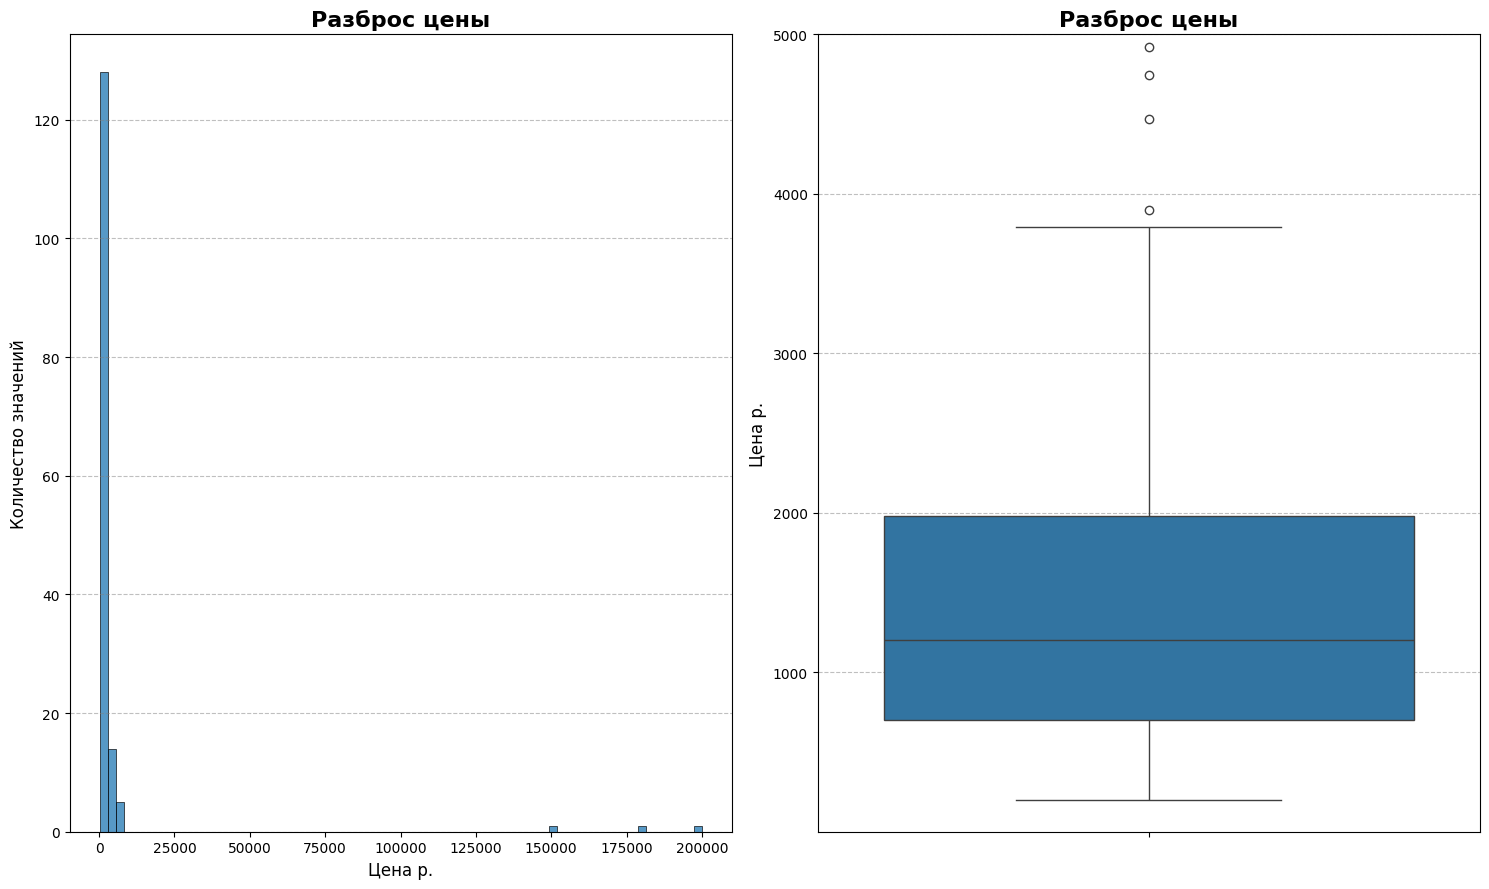

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axs = plt.subplots(1, 2, figsize=(15, 9))

sns.histplot(
    data=df,
    x='amount',
    bins=75,
    ax=axs[0]
)

axs[0].set_title('Разброс цены', fontsize=16, fontweight='bold')
axs[0].set_xlabel('Цена р.', fontsize=12)
axs[0].set_ylabel('Количество значений', fontsize=12)
axs[0].grid(axis='y', alpha=0.5, color='gray', linestyle='--')

sns.boxplot(
    data=df,
    y='amount',
    gap = 2,
    ax=axs[1]
)

axs[1].set_title('Разброс цены', fontsize=16, fontweight='bold')
axs[1].set_ylabel('Цена р.', fontsize=12)
axs[1].grid(axis='y', alpha=0.5, color='gray', linestyle='--')
axs[1].set_ylim(1, 5000)

plt.tight_layout()

avg_amount = df['amount'].mean().round(2)
diff_mean_and_median = round(avg_amount - quantilies_amount[1], 3)

display(Markdown(f'''> На гистограмме наглядно видим разброс данных, чаще всего значения находятся в интервале от 1000 до 5000. Выбросы - за пределами 25_000'))
>
> На ящике с усами мы обрежем выбросы более 10_000, и видим, что медиана равна **_{quantilies_amount[1]}_**, 25 и 75 перцентили равны: **_{quantilies_amount[0]}_** и **_{quantilies_amount[2]}_** соответсвенно'))
>
> Если мы используем среднее для цены, тогда значение будет: **_{avg_amount}_**, из-за тех трех выбросов, среднее отличается от медианы на **_{diff_mean_and_median}!_**'))
>
> **_Вывод:_** Необходимо использовать медиану, так как выбросы сильно искажают среднее.'''))
# Я не стал считать медиану отдельно, а просто взял значения из quantilies_amount, предварительно превратив Series в List, для удобной работы

> ## 4/5. Статистическая проверка гипотез (с обоснованием выбранного метода) + Рекомендации
> 1. **_Региональные различия в структуре спроса._** Медианный чек в Новосибирске выше, чем в других регионах, за счет преобладания заказов из более дорогих товарных категорий (например, электроники), а не из-за более высокой покупательной способности населения или скорости доставки.
> 2. **_Влияние промо-механик на средний чек._** Увеличение размера скидки стимулирует клиентов к покупке большего количества товаров или более дорогих позиций, что приводит к росту медианного чека.
> 3. **_Зависимость риска возврата от способа оплаты._** Доля возвратов статистически значимо выше при оплате наличными при получении по сравнению с онлайн-оплатой картой, так как отсутствие финансовой транзакции до момента получения снижает психологический барьер отказа от заказа.

,order_id,customer_id,order_date,product_category,amount,discount,payment_method,delivery_time_days,customer_rating,is_returned,region
0,ORD_0001,CUST_052,2024-11-26,Книги,1285.94,10,Наличные,14.0,4.0,False,Москва
1,ORD_0002,CUST_015,2024-10-27,Электроника,678.46,0,Наличные,NaN,5.0,False,Москва
2,ORD_0003,CUST_072,2024-11-26,Электроника,1159.61,0,Карта,2.0,1.0,True,Казань
3,ORD_0004,CUST_061,2024-11-21,Книги,805.73,0,Карта,2.0,5.0,False,СПб
4,ORD_0005,CUST_021,2024-10-13,Электроника,1200.88,0,Карта,6.0,NaN,False,Москва


"['Москва' 'Казань' 'СПб' 'Екатеринбург' 'Новосибирск'] -> длина 5"

,region,amount
0,Екатеринбург,1320.330
1,Казань,1336.065
2,Москва,1097.865
3,Новосибирск,1568.855
4,СПб,1005.250


,region,delivery_time_days
0,Екатеринбург,6.800
1,Казань,6.933
2,Москва,6.818
3,Новосибирск,7.810
4,СПб,6.657


C:\Users\Евгений\AppData\Local\Temp\ipykernel_1324\3887368903.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
C:\Users\Евгений\AppData\Local\Temp\ipykernel_1324\3887368903.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


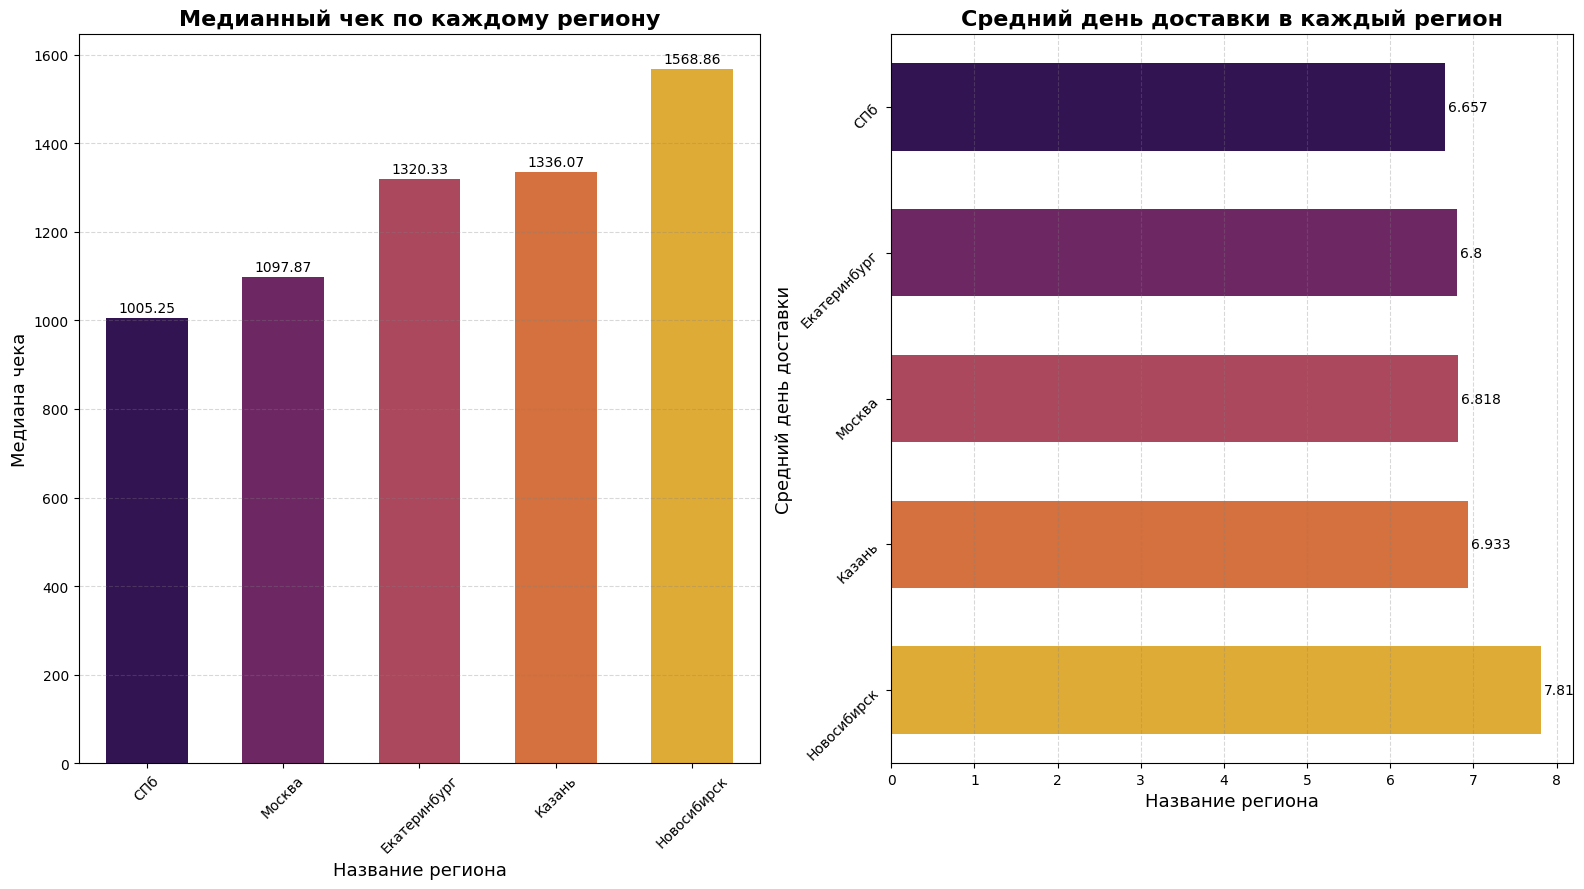

In [8]:
display(df.head()) # Просмотрим текущий Df
display(f'{df['region'].unique()} -> длина {len(df['region'].unique())}') # Просмотрим уникальные регионы

group_region_by_amount_median = df.groupby('region', as_index=False)['amount'].median()
display(group_region_by_amount_median) # Видим, что большая медиана у Новосибирска - проверим дни доставки на регионах

group_region_by_deliv_days_median = df.groupby('region', as_index=False)['delivery_time_days'].mean().round(3)
display(group_region_by_deliv_days_median) # Видим что у Новосибирска средний день доставки - 7 (ближе к 8), в отличие от остальных около 6
# Это говорит о том, что дни доставки не зависят от цены - потому что цена у Новосибирска самая большая, а также и день доставки самые большие!

# ФИКСИРУЕМ: если хочу строить график для group by, тогда reset_index - ОБЯЗАТЕЛЬНО!

# Визуализация двух группировок по регионам
fig, axs = plt.subplots(1, 2, figsize = (16, 9))

sns.barplot(
    data=group_region_by_amount_median.sort_values(by='amount'), # Медианный чек
    x='region',
    y='amount',
    width=0.6,
    palette='inferno',
    ax=axs[0]
)

for data in axs[0].containers:
    axs[0].bar_label(container=data, padding=2)

axs[0].set_title('Медианный чек по каждому региону', fontsize=16, fontweight='bold')
axs[0].set_xlabel('Название региона', fontsize=13)
axs[0].set_ylabel('Медиана чека', fontsize=13)
axs[0].grid(linestyle='--', axis='y', alpha=0.3, color='gray')
axs[0].tick_params(axis='x', labelrotation=45)


sns.barplot(
    data=group_region_by_deliv_days_median.sort_values(by='delivery_time_days'), # Средний день доставки\
    x='delivery_time_days',
    y='region',
    width=0.6,
    palette='inferno',
    ax=axs[1]
)

for data in axs[1].containers:
    axs[1].bar_label(container=data, padding=2)

axs[1].set_title('Средний день доставки в каждый регион', fontsize=16, fontweight='bold')
axs[1].set_xlabel('Название региона', fontsize=13)
axs[1].set_ylabel('Средний день доставки', fontsize=13)
axs[1].grid(linestyle='--', axis='x', alpha=0.3, color='gray')
axs[1].tick_params(axis='y', labelrotation=45)

plt.tight_layout()

In [9]:
# На данном этапе создание графиков излишне, потому что мы не ответили на нашу гипотезу.
# Мы подтвердили, что столбец delivery_time_days не способствует увеличению цены по городу Новосибирск -> подтверждение части гипотезы!
display(df['product_category'].unique()) # Просмотрим, в каком городе большее количество электроники (самой большой категории из присутствующих)
display(df['region'].unique()) 

big_price_category = df.groupby('product_category')['amount'].sum() # Выведем общюю цену по каждой категории
display('Чек по категориям с выбросами: ')
display(big_price_category) # Видим, что самая дорогая категория - Книги, выведем ниже все книги

all_books = df.loc[df['product_category'] == 'Книги'] # Мы знаем что у нас 3 выброса - 2 из них в категории книги, значит последний - в электронике. (Проверим) ->
all_electronics = df.loc[df['product_category'] == 'Электроника'] # Подтвердилось.
# display(all_books) # Выброс в 200_000 тысяч находится в Новосибирске!
# display(all_electronics) # Как мы проверяли до этого 10, 25, 50 позиции - Выбросы, это подтвердилось
# Если мы отрежем выбросы, то увидим настоящую самую дорогую категорию (Выбросы могли быть у любой категории - заказала компания партию одежды и так далее. Настоящая дорогая категория ценится не самой большым чеком, а насколько ее один товар может бить по чеку)
# Если мы закажем два телевизора и две книги, то наш первый чек будет 50_000, а второй 3_000 - колосальная разница! Проверим ->
big_price_category_not_emissions = df[df['amount'] < 10_000].groupby('product_category')['amount'].sum() # Выведем общюю цену по каждой категории
display('Чек по категориям без выбросов: ')
display(big_price_category_not_emissions) # Видим, что самая дорогая категория - Книги, выведем ниже все книги без выбросов
# display(df.loc[(df['amount'] < 10_000) & (df['product_category'] == 'Книги')])

big_price_category_not_emissions = df[df['amount'] < 10_000].groupby('product_category')['amount'].count() # Выведем количество без выбросов по каждой категории
display('Количество товаров по категориям без выбросов: ')
display(big_price_category_not_emissions) # Видим, что самая дорогая категория - Книги, выведем ниже все книги

# Видим, что самая дорогая категория без выбросов - Книги, их количество заказов 36 и сумма ~67500, смотрим на электронику (которая должна быть дороже), количество заказов 43, чек ~56200
# Опираемся на категория, как на самую дорогую - "Книги"

group_by_region_median = df.groupby(['product_category', 'region'])['amount'].median() # Смотрим медианный разрез по регионам и категориям
display(group_by_region_median) 
# Медианный чек доставки в Новосибирск книг - на втором месте. Первое - Казань (~1800 против ~2800)
# Новосибирск - лидер медиан по категориям "Еда" и "Одежда" - "Одежда": по количеству заказов на равне с книгами, но чек без выбросов ~63700 (на ~4000 тысячи меньше чем у книг)

group_by_region_mean = df.groupby(['product_category', 'region'])['amount'].mean().round(3)
display(group_by_region_mean)

pc_novosib_electr = df.loc[(df['region'] == 'Новосибирск') & (df['product_category'] == 'Книги')]
display(pc_novosib_electr)

# display(df.loc[(df['region'] == 'Новосибирск') & (df['product_category'] == 'Одежда') | (df['product_category'] == 'Еда')].groupby('product_category')['amount'].median())
display(group_by_region_median.iloc[3::5]) # Выведем все категории по Новосибирску

array(['Книги', 'Электроника', 'Одежда', 'Еда', 'Игрушки'], dtype=object)

array(['Москва', 'Казань', 'СПб', 'Екатеринбург', 'Новосибирск'],
      dtype=object)

'Чек по категориям с выбросами: '

product_category
Еда             25126.74
Игрушки         19021.49
Книги          417588.08
Одежда          63723.58
Электроника    236230.70
Name: amount, dtype: float64

'Чек по категориям без выбросов: '

product_category
Еда            25126.74
Игрушки        19021.49
Книги          67587.58
Одежда         63723.58
Электроника    56229.95
Name: amount, dtype: float64

... (2 outputs left out)

product_category  region      
Еда               Екатеринбург     962.490
                  Казань          1207.410
                  Москва          1043.190
                  Новосибирск     2085.895
                  СПб              934.825
Игрушки           Екатеринбург    2218.285
                  Казань          1062.730
                  Москва          1495.945
                  Новосибирск      278.520
                  СПб             1669.045
Книги             Екатеринбург    1165.190
                  Казань          2835.505
                  Москва          1285.940
                  Новосибирск     1812.890
                  СПб             1000.610
Одежда            Екатеринбург    1373.060
                  Казань          1107.740
                  Москва          1080.080
                  Новосибирск     1421.310
                  СПб              571.240
Электроника       Екатеринбург    1661.500
                  Казань          1578.975
                  Москв

product_category  region      
Еда               Екатеринбург      962.490
                  Казань           1755.887
                  Москва           1069.728
                  Новосибирск      2085.895
                  СПб              1223.990
Игрушки           Екатеринбург     2218.285
                  Казань           1062.730
                  Москва           1473.808
                  Новосибирск       278.520
                  СПб              1669.045
Книги             Екатеринбург     1742.182
                  Казань           2835.505
                  Москва          13483.359
                  Новосибирск     30437.491
                  СПб              1350.914
Одежда            Екатеринбург     2427.608
                  Казань           1107.740
                  Москва           1688.985
                  Новосибирск      2048.706
                  СПб              1346.061
Электроника       Екатеринбург     1434.127
                  Казань          23905.511
 

,order_id,customer_id,order_date,product_category,amount,discount,payment_method,delivery_time_days,customer_rating,is_returned,region
25,ORD_0026,CUST_060,2024-11-21,Книги,200000.00,0,Онлайн,7.0,1.0,False,Новосибирск
51,ORD_0052,CUST_047,2024-10-02,Книги,2065.92,15,Карта,NaN,1.0,False,Новосибирск
53,ORD_0054,CUST_078,2024-11-13,Книги,1812.89,0,Наличные,8.0,1.0,False,Новосибирск
74,ORD_0075,CUST_040,2024-10-16,Книги,1406.31,0,Карта,13.0,5.0,False,Новосибирск
111,ORD_0112,CUST_078,2024-11-04,Книги,4919.37,20,Карта,NaN,NaN,False,Новосибирск
133,ORD_0134,CUST_071,2024-10-19,Книги,1654.99,0,Онлайн,5.0,NaN,False,Новосибирск
141,ORD_0142,CUST_006,2024-11-02,Книги,1202.96,0,Наличные,6.0,NaN,False,Новосибирск


product_category  region     
Еда               Новосибирск    2085.895
Игрушки           Новосибирск     278.520
Книги             Новосибирск    1812.890
Одежда            Новосибирск    1421.310
Электроника       Новосибирск    1430.600
Name: amount, dtype: float64

> Вывод по гипотезе №1: Медианный чек в Новосибирске выше, чем в других регионах, за счет преобладания заказов из более дорогих товарных категорий (например, электроники), а не из-за более высокой покупательной способности населения или скорости доставки.
> 1. Вердикт: Гипотеза частично подтвердилась.
> 2. Факты: 
>       - В самой дорогой категории (книги), Новосибирск отстает от Казани на ~1000 рублей;
>       - Средняя доставка в днях у Новосибирска также больше, чем у других регионов (почти 8 у Новосибирска, против 6-7 дней у других) -> Скорость доставки не приоритет, часть гипотезы подтвердилась;
>       - Новосибирск является медианным лидером по категориям "Одежда" и "Еда" и средний арифметический лидер по категори "Книги".
> 3. Нюанс: Абсолютное доминирование Новосибирска в категории "Книги" по суммарной выручке является статистической иллюзией, созданной одним оптовым заказом (выбросом - 200_000) от B2B-клиента, показатель суммы товаров по категории "Книги", показан только на клиентах B2C.
> 4. Рекомендации: Убрать B2B-клиентов в отдельный стобец/таблицу, чтобы не размывать данные с B2C-клиентами

In [10]:
display(df[['amount', 'discount']].head(15)) # Просмотрим колонки "скидка" и "тотал_чек"
display(f'Все доступные скидки: {sorted(df['discount'].unique().tolist())}') # Просмотрим уникальные значения скидки

group_discount_by_amount = df.groupby('discount', as_index=False)['amount'].median() # Сгрупируем значения скидки и медийный чек
display(group_discount_by_amount) # .max() - самое большое значение
# Мы видим, что увеличение размера скидки - не приводит к размеру медийного чека, самое большое значение на скидке 15 - 1904, дальше значение падает. Смотрим почему.

,amount,discount
0,1285.94,10
1,678.46,0
2,1159.61,0
3,805.73,0
4,1200.88,0
5,1862.56,5
6,3900.32,0
7,407.38,5
8,6041.62,20
9,230.06,0


'Все доступные скидки: [0, 5, 10, 15, 20, 25, 30]'

,discount,amount
0,0,1203.755
1,5,1113.045
2,10,852.970
3,15,1904.770
4,20,928.440
5,25,1778.285
6,30,1513.850


In [ ]:
# display(Markdown('> ##### Медийный чек по категориям и скидке'))
# group_dicount_category = df.groupby(['product_category', 'discount'], as_index=False)['amount'].median() # Сгруппируем медийный чек по категориям и скидке
# display(group_dicount_category)

# display(Markdown('> ##### Количество доставок по категориям и скидке'))
# group_dicount_category = df.groupby(['product_category', 'discount'], as_index=False)['amount'].count() # Сгруппируем количество доставок по категориям и скидке
# display(group_dicount_category)

# fig, axs = plt.subplots(figsize=(10, 8))

# sns.scatterplot(
#     data=gro
# )

In [12]:
# Видим, что медийный чек увеличивается только на товарах категории "Книги", у остальных лидером являются более маленькие скидки. На товары категории "Книги", скидка 30% способствует увеличению медийного чека
# Но посмотрим на количество, и увидмим, что всего книги по 30% скидке взяли один раз, но по большой цене (в отличие например от того, где скидка 0, медиана 1466)
display(df[df['product_category'] == 'Книги'].groupby('discount')['amount'].mean())
display(df[df['product_category'] == 'Одежда'])
# display(df[(df['product_category'] == 'Книги') & (df['discount'] == 20)])
display(df[(df['discount'] == 20) | (df['discount'] == 15)])

discount
0     12728.340000
5     25623.805000
10     1396.880000
15     2065.920000
20     2828.318571
25     2817.350000
30     4466.110000
Name: amount, dtype: float64

,order_id,customer_id,order_date,product_category,amount,discount,payment_method,delivery_time_days,customer_rating,is_returned,region
6,ORD_0007,CUST_075,2024-10-03,Одежда,3900.32,0,Онлайн,1.0,1.0,False,Москва
12,ORD_0013,CUST_030,2024-11-06,Одежда,1373.06,0,Карта,1.0,5.0,False,Екатеринбург
19,ORD_0020,CUST_076,2024-11-28,Одежда,629.97,0,Карта,10.0,2.0,True,Москва
23,ORD_0024,CUST_059,2024-10-24,Одежда,1814.75,0,Наличные,12.0,5.0,False,Москва
27,ORD_0028,CUST_062,2024-11-18,Одежда,1787.00,0,Онлайн,12.0,4.0,False,Новосибирск
29,ORD_0030,CUST_047,2024-11-21,Одежда,1204.55,0,Карта,7.0,3.0,False,Новосибирск
39,ORD_0040,CUST_039,2024-11-28,Одежда,1115.22,0,Наличные,13.0,1.0,True,Москва
42,ORD_0043,CUST_060,2024-10-02,Одежда,1421.31,0,Наличные,9.0,NaN,False,Новосибирск
47,ORD_0048,CUST_060,2024-11-01,Одежда,5848.32,0,Наличные,12.0,5.0,False,Новосибирск
49,ORD_0050,CUST_044,2024-10-01,Одежда,415.15,10,Наличные,2.0,3.0,False,СПб


,order_id,customer_id,order_date,product_category,amount,discount,payment_method,delivery_time_days,customer_rating,is_returned,region
8,ORD_0009,CUST_003,2024-10-06,Книги,6041.62,20,Карта,14.0,1.0,True,Москва
11,ORD_0012,CUST_002,2024-10-09,Электроника,1755.75,15,Карта,4.0,4.0,True,Казань
14,ORD_0015,CUST_002,2024-11-20,Книги,928.44,20,Наличные,13.0,1.0,False,Москва
17,ORD_0018,CUST_021,2024-10-24,Книги,2163.93,20,Наличные,3.0,2.0,False,Москва
34,ORD_0035,CUST_003,2024-11-18,Книги,921.36,20,Карта,7.0,3.0,False,Екатеринбург
51,ORD_0052,CUST_047,2024-10-02,Книги,2065.92,15,Карта,NaN,1.0,False,Новосибирск
54,ORD_0055,CUST_036,2024-10-26,Книги,1085.94,20,Карта,14.0,1.0,True,СПб
55,ORD_0056,CUST_050,2024-11-01,Электроника,534.96,20,Наличные,11.0,2.0,False,Москва
58,ORD_0059,CUST_006,2024-11-24,Электроника,2392.50,15,Карта,5.0,5.0,False,Екатеринбург
71,ORD_0072,CUST_072,2024-10-22,Одежда,355.68,20,Наличные,13.0,1.0,False,СПб


> Вывод по гипотезе №2: Увеличение размера скидки стимулирует клиентов к покупке большего количества товаров или более дорогих позиций, что приводит к росту медианного чека.
> 1. Вердикт: Гипотеза не подтвердилась.
> 2. Факты:
>       - Рост медианного чека растет только в категории "Книги" (Из прошлой гипотезы нам известно, что это самая дорогая категория);'=
>       - Количесвто преобритаемых товаров больше всего на товаров без скидки;
>       - Среднее значение на товарах с минимальной скидкой или отсутвие ее, уходят дальше других значений из-за выбросов.
> 3. Оговорка: 
>       - Самые большие скидки в самой дорогой категории, были взяты 1 раз, что отличает от товаров без скидки, которые были куплены 18 раз. (Разница в среднем: ~8 тысяч, Разница в медиане: ~ -3 тысячи (медиана 30% скидки больше, чем без скидки, с средним - наоборот));
>       - Товары с большой скидкой редко берут -> чаще всего скидки дают B2B-клиентам (как спонсортсво или покупка оптом), при этом выбросы как раз таки на товарах без скидки или она минимальная.
> 4. Рекомендации: 
>       - На товары категории "Игрушки" и "Одежда" стоит обратить внимание, "Одежда" - является второй категорией по ценовому сегменту, стоит предложить привлекающую рекламу, чтобы люди обращали внимание на эти категории (особенно "Одежда"), приход дохода и увеличение медианного чека на категории с низким медианным чеком.

In [12]:
display(df.head()) # Просмотрим текущий Df 

group_return_and_pay = df.groupby(['payment_method', 'is_returned'])['is_returned'].count() # Просмотрим количество возвратов и получения у каждой категории
display(group_return_and_pay) # По наличному было возвращено 3 товара, онлайн - 4, карта - 9, по карте заказывают чаще всего!

# Сделаем процентами: Мой вариант - формулами
# card = round(group_return_and_pay.iloc[1] / df.loc[df['payment_method'] == 'Карта', 'is_returned'].count() * 100, 2)
# cash = round(group_return_and_pay.iloc[3] / df.loc[df['payment_method'] == 'Наличные', 'is_returned'].count() * 100, 2)
# online = round(group_return_and_pay.iloc [5] / df.loc[df['payment_method'] == 'Онлайн', 'is_returned'].count() * 100, 2)

# display(Markdown(f'Процент отменненных, при оплате картой: {card} %'))
# display(Markdown(f'Процент отменненных, при оплате наличными: {cash} %')) # Видим что процент возврата наличными В СВОЕЙ ГРУППЕ - самый маленький, по сравнению в другими группами, по этому наша гипотеза не подтвердилась
# display(Markdown(f'Процент отменненных, при оплате онлайн: {online} %'))

# Вариант ИИ (на заметку) - средним арфиметическим
return_rates = (df.groupby('payment_method')['is_returned'].mean() * 100).round(2)
display(return_rates)

,order_id,customer_id,order_date,product_category,amount,discount,payment_method,delivery_time_days,customer_rating,is_returned,region
0,ORD_0001,CUST_052,2024-11-26,Книги,1285.94,10,Наличные,14.0,4.0,False,Москва
1,ORD_0002,CUST_015,2024-10-27,Электроника,678.46,0,Наличные,NaN,5.0,False,Москва
2,ORD_0003,CUST_072,2024-11-26,Электроника,1159.61,0,Карта,2.0,1.0,True,Казань
3,ORD_0004,CUST_061,2024-11-21,Книги,805.73,0,Карта,2.0,5.0,False,СПб
4,ORD_0005,CUST_021,2024-10-13,Электроника,1200.88,0,Карта,6.0,NaN,False,Москва


payment_method  is_returned
Карта           False          62
                True            9
Наличные        False          44
                True            3
Онлайн          False          28
                True            4
Name: is_returned, dtype: int64

payment_method
Карта       12.68
Наличные     6.38
Онлайн      12.50
Name: is_returned, dtype: float64

> Вывод по гипотезе №3: Доля возвратов статистически значимо выше при оплате наличными при получении по сравнению с онлайн-оплатой картой, так как отсутствие финансовой транзакции до момента получения снижает психологический барьер отказа от заказа.
> 1. Вердикт: Гипотеза не подтвердилась.
> 2. Факты: Количество возвращаемых заказов, было больше у заказов, оплаченные картой (9 возвратов - 12.68% в группе). Наличные имеют минимальный процент возвратов в группе, среди всех методов. (3 возврата - 6.38%)
> 3. Оговорка: Оплата картой или онлайн более удобны, нежели оплата наличными. Также и возврат - онлайн/карта, куда удобнее, нежели наличными. "Из-за малого абсолютного количества возвратов (9 и 3) данный вывод имеет низкую статистическую значимость и требует проверки на большем объеме данных"
> 4. Рекомендации: 
>       - Лишние возвраты портят репутацию компании, если люди редко возвращают наличными, стоит перевести кнопку оплаты наличными выше, чем кнопка картой/онлайн;
>       - Предложить скидку 20% на заказ по категории "Одежда" или 15% - на "Игрушки" (Их медийный чек очень низок (330 и 278 соответсвенно)). Мы убьем сразу двух зайцев - подним медийный чек двух категорий, а также уменьшим лишние возвраты, так как они будут оплачиваться наличными.
>       - Ввести функцию "Оплата после получения", на наличный метод оплаты. Людям психологически будет приятно знать, что пока они не увидят состояние заказа, то не отдадут деньги.